# Explore the AequilibraE example projects

Two of the projects in `ae-projects/`:

* **hearn-example**: the 4-node Braess network
* **sioux-falls**: Sioux Falls imported from `gmns-data/sioux_falls`

Create the projects first from the repository root if not already:

```bash
uv run create-ae-projects --overwrite
```

The assignments below save their link flows in each project's results database as `ae_ue`, `ae_so` and `ae_tolled`. `gurobi_expts.ipynb` reads them, so we need to run this first.

In [1]:
import os
from pathlib import Path

os.environ["AEQ_SHOW_PROGRESS"] = "FALSE"  # no AequilibraE progress bars in the notebook

import gurobipy as gp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from aequilibrae import Project
from aequilibrae.paths import TrafficAssignment, TrafficClass

# Find the AE Projects root
AE_DIR = Path("../ae-projects").resolve()
sorted(p.name for p in AE_DIR.iterdir() if p.is_dir())

['hearn-example', 'nine-node', 'sioux-falls']

In [2]:
def plot_network(project, title, label_nodes=True, routes=None):
    """Plot the network; links in `routes` (list of lists of link ids) are drawn in crimson and labelled."""
    links = project.network.links.data
    nodes = project.network.nodes.data
    ax = links.plot(color="steelblue", linewidth=1.5, figsize=(6, 6))
    nodes.plot(ax=ax, color="brown", markersize=20, zorder=3)
    if label_nodes:
        for _, row in nodes.iterrows():
            ax.annotate(str(row.node_id), (row.geometry.x, row.geometry.y),
                        xytext=(4, 4), textcoords="offset points", fontsize=8)
    if routes:
        route_ids = {abs(int(l)) for route in routes for l in route}
        route_links = links[links.link_id.isin(route_ids)]
        route_links.plot(ax=ax, color="crimson", linewidth=3, zorder=2)
    ax.set_title(title)
    ax.set_axis_off()
    return ax


def demand_df(project, matrix_name, core="volume"):
    mat = project.matrices.get_matrix(matrix_name)
    index = mat.index.flatten() if hasattr(mat.index, "flatten") else mat.index
    df = pd.DataFrame(mat.get_matrix(core), index=index, columns=index)
    mat.close()
    return df

In [3]:
def plot_demand(project, matrix_name, core="volume", title=None):
    """Heatmap of an OD demand matrix stored in the project."""
    df = demand_df(project, matrix_name, core)
    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(df.to_numpy(), cmap="viridis")
    ax.set_xticks(range(len(df.columns)), df.columns, fontsize=6)
    ax.set_yticks(range(len(df.index)), df.index, fontsize=6)
    ax.set_xlabel("destination zone")
    ax.set_ylabel("origin zone")
    ax.set_title(title or matrix_name)
    fig.colorbar(im, ax=ax, label="trips")
    return ax

## 1. hearn-example (Braess network)

In [4]:
hearn = Project()
hearn.open(str(AE_DIR / "hearn-example"))

In [5]:
hearn.network.links.data

,ogc_fid,link_id,a_node,b_node,direction,distance,modes,link_type,name,speed_ab,speed_ba,travel_time_ab,travel_time_ba,capacity_ab,capacity_ba,vdf_fftt,vdf_alpha,vdf_beta,geometry
0,1,1,1,2,1,1569.034715,c,default,None,None,None,None,None,4000,None,1.00,40,1,"LINESTRING (0 0, 0.01 0.01)"
1,2,2,1,3,1,1569.034715,c,default,None,None,None,None,None,4000,None,45.00,0,1,"LINESTRING (0 0, 0.01 -0.01)"
2,3,3,2,4,1,1569.034715,c,default,None,None,None,None,None,4000,None,45.00,0,1,"LINESTRING (0.01 0.01, 0.02 0)"
3,4,4,3,4,1,1569.034715,c,default,None,None,None,None,None,4000,None,1.00,40,1,"LINESTRING (0.01 -0.01, 0.02 0)"
4,5,5,2,3,1,2211.485517,c,default,None,None,None,None,None,4000,None,0.01,0,1,"LINESTRING (0.01 0.01, 0.01 -0.01)"


In [6]:
print("links:", len(hearn.network.links.data), "| nodes:", len(hearn.network.nodes.data))
print("modes:", {k: v.mode_name for k, v in hearn.network.modes.all_modes().items()})

links: 5 | nodes: 4
modes: {'b': 'bicycle', 'c': 'car', 't': 'transit', 'w': 'walk'}


In [7]:
hearn.network.nodes.data[["node_id", "is_centroid", "modes", "geometry"]]

,node_id,is_centroid,modes,geometry
0,1,1,c,POINT (0 0)
1,2,0,c,POINT (0.01 0.01)
2,3,0,c,POINT (0.01 -0.01)
3,4,1,c,POINT (0.02 0)


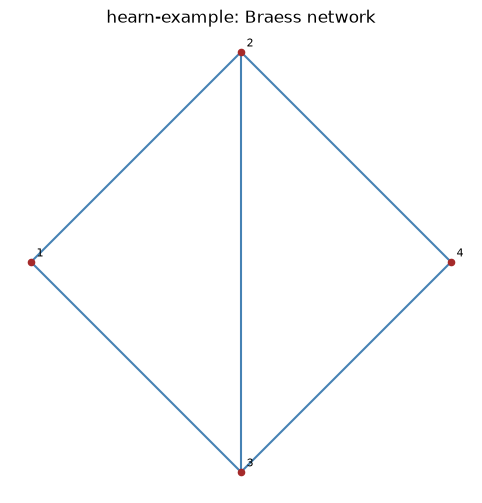

In [8]:
plot_network(hearn, "hearn-example: Braess network");

In [9]:
print(hearn.matrices.list()[["name", "file_name", "cores"]])
demand_df(hearn, "hearn-example_demand")

                   name                 file_name  cores
0  hearn-example_demand  hearn-example_demand.omx      1


,1,4
1,0.0,4000.0
4,0.0,0.0


In [10]:
hearn.network.build_graphs(modes=["c"])
g = hearn.network.graphs["c"]

In [11]:
g.set_graph("vdf_fftt")
g.set_skimming(["vdf_fftt"])
g.set_blocked_centroid_flows(False)

res = g.compute_path(1, 4)
print("nodes:", res.path_nodes)
print("links:", res.path)
print("free-flow time:", res.milepost[-1])

nodes: [1 2 3 4]
links: [1 5 4]
free-flow time: 2.01


## 2. sioux-falls (from GMNS)

The BPR parameters from the GMNS file are kept as link fields `vdf_fftt`, `vdf_alpha` and `vdf_beta`.

In [8]:
sf = Project()
sf.open(str(AE_DIR / "sioux-falls"))

sf_links = sf.network.links.data
sf_nodes = sf.network.nodes.data
print("links:", len(sf_links), "| nodes:", len(sf_nodes),
      "| centroids:", int(sf_nodes.is_centroid.sum()))
print("modes:", {k: v.mode_name for k, v in sf.network.modes.all_modes().items()})
print("link types:", sorted(sf_links.link_type.unique()))

links: 76 | nodes: 24 | centroids: 24
modes: {'b': 'bicycle', 'c': 'car', 't': 'transit', 'w': 'walk'}
link types: ['1']


In [13]:
type(sf_nodes)

geopandas.geodataframe.GeoDataFrame

In [14]:
sf_links[["link_id", "a_node", "b_node", "direction", "modes", "distance",
          "capacity_ab", "speed_ab", "vdf_fftt", "vdf_alpha", "vdf_beta"]].head(10)

,link_id,a_node,b_node,direction,modes,distance,capacity_ab,speed_ab,vdf_fftt,vdf_alpha,vdf_beta
0,1,1,2,1,c,4839.924757,25900.200640,96.54,6,0.15,4
1,2,1,3,1,c,4440.408290,23403.473190,96.54,4,0.15,4
2,3,2,1,1,c,4839.924757,25900.200640,96.54,6,0.15,4
3,4,2,6,1,c,2025.398302,4958.180928,96.54,5,0.15,4
4,5,3,1,1,c,4440.408290,23403.473190,96.54,4,0.15,4
5,6,3,4,1,c,2423.803402,17110.523720,96.54,4,0.15,4
6,7,3,12,1,c,3258.599666,23403.473190,96.54,4,0.15,4
7,8,4,3,1,c,2423.803402,17110.523720,96.54,4,0.15,4
8,9,4,5,1,c,1260.999457,17782.794100,96.54,2,0.15,4
9,10,4,11,1,c,2169.229297,4908.826730,96.54,6,0.15,4


In [15]:
sf_links[["capacity_ab", "vdf_fftt", "vdf_alpha", "vdf_beta", "distance"]].describe()

,capacity_ab,vdf_fftt,vdf_alpha,vdf_beta,distance
count,76.000000,76.000000,76.00,76.0,76.000000
mean,10247.206327,4.131579,0.15,4.0,2096.802235
std,7358.655049,1.730835,0.00,0.0,1175.013523
min,4823.950831,2.000000,0.15,4.0,369.811503
25%,4958.180928,3.000000,0.15,4.0,1578.948244
50%,5109.391136,4.000000,0.15,4.0,1682.334639
75%,14564.753150,5.000000,0.15,4.0,2423.803402
max,25900.200640,10.000000,0.15,4.0,6010.484708


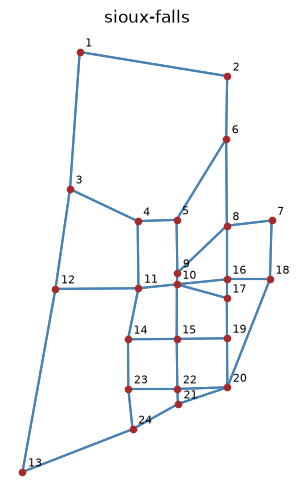

In [16]:
plot_network(sf, "sioux-falls");

In [17]:
print(sf.matrices.list()[["name", "file_name", "cores"]])

                 name               file_name  cores
0  sioux-falls_demand  sioux-falls_demand.omx      1


In [18]:
sf_demand = demand_df(sf, "sioux-falls_demand")
print("total trips:", sf_demand.to_numpy().sum())
sf_demand.iloc[:8, :8]

total trips: 360600.0


,1,2,3,4,5,6,7,8
1,0.0,100.0,100.0,500.0,200.0,300.0,500.0,800.0
2,100.0,0.0,100.0,200.0,100.0,400.0,200.0,400.0
3,100.0,100.0,0.0,200.0,100.0,300.0,100.0,200.0
4,500.0,200.0,200.0,0.0,500.0,400.0,400.0,700.0
5,200.0,100.0,100.0,500.0,0.0,200.0,200.0,500.0
6,300.0,400.0,300.0,400.0,200.0,0.0,400.0,800.0
7,500.0,200.0,100.0,400.0,200.0,400.0,0.0,1000.0
8,800.0,400.0,200.0,700.0,500.0,800.0,1000.0,0.0


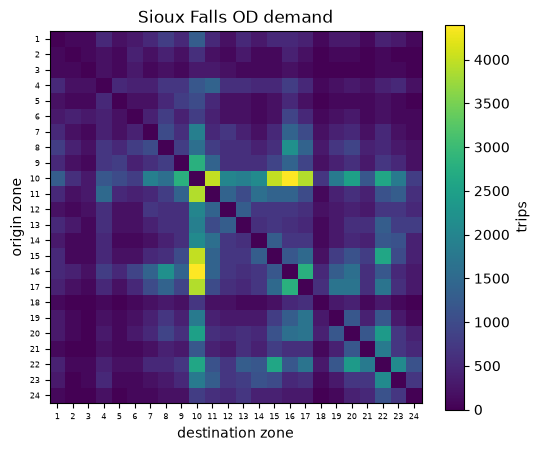

In [19]:
plot_demand(sf, "sioux-falls_demand", title="Sioux Falls OD demand");

### Shortest path on free-flow time

In [20]:
sf.network.build_graphs(modes=["c"])
g = sf.network.graphs["c"]
g.set_graph("vdf_fftt")
g.set_skimming(["vdf_fftt", "distance"])
g.set_blocked_centroid_flows(False)  # every node is a centroid in Sioux Falls

res = g.compute_path(1, 20)
print("nodes:", res.path_nodes)
print("links:", res.path)
print("free-flow time:", res.milepost[-1])

nodes: [ 1  2  6  8  7 18 20]
links: [ 1  4 16 20 18 56]
free-flow time: 22.0


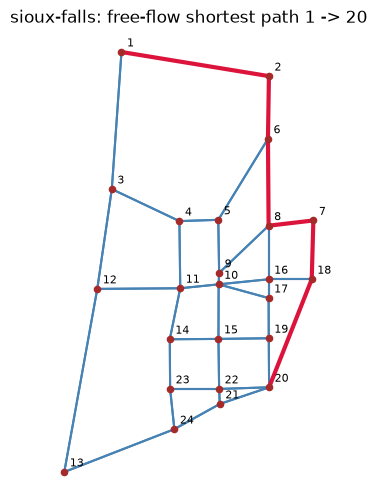

In [21]:
plot_network(sf, "sioux-falls: free-flow shortest path 1 -> 20", routes=[list(res.path)]);

In [22]:
sf.run.graph_summary()

{'c': {'num_links': 76,
  'num_nodes': 24,
  'num_zones': 24,
  'compact_num_links': 76,
  'compact_num_nodes': 24}}

In [ ]:
from aequilibrae.paths.route_choice import RouteChoice
## Experiments: Not useful for now but later when we study trip distribution/ elastic demand/ Stichastic User Equillibrium
rc = RouteChoice(g)
rc.set_choice_set_generation(
    "bfsle",            # or "lp" (link-penalisation)
    max_routes=10,      # generous upper bound
    max_depth=10,       # BFSLE: ~10 small nets, ~5 large
    max_misses=20,     # stop after this many duplicate routes
    penalty=1.0,       # 1.0 = pure link removal; >1 also penalises reused links
)
rc.prepare([(1, 20)])                     # or a list of OD pairs
rc.execute(perform_assignment=False)
df = rc.get_results()

In [24]:
routes_c = df['route set'].apply(lambda x: [int(l) for l in x]).tolist()

In [25]:
df['route set'].tolist()

[array([ 2,  7, 37, 39, 75, 65, 68]),
 array([ 1,  4, 16, 22, 50, 56]),
 array([ 2,  7, 37, 39, 76, 72, 68]),
 array([ 2,  6,  9, 12, 16, 20, 18, 56]),
 array([ 1,  4, 16, 22, 49, 53, 59]),
 array([ 2,  6,  9, 13, 25, 29, 50, 56]),
 array([ 2,  7, 37, 39, 75, 64]),
 array([ 1,  4, 16, 20, 18, 56])]

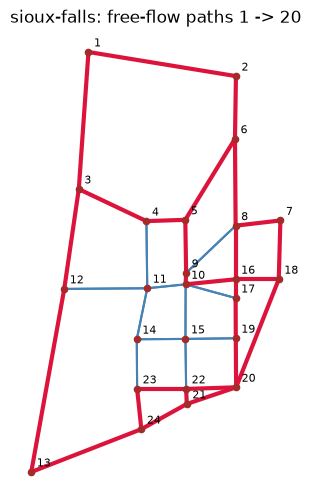

In [26]:
plot_network(sf, "sioux-falls: free-flow paths 1 -> 20", routes=routes_c);

## 3. Assignment and tolls through AE

We assume only single mode networks. The assignment is split into four steps:

1. `build_graph`: the car graph, optionally with link tolls. Tolls are added to the graph only, never to the project database.
2. `traffic_class`: the demand matrix on that graph. If the graph has tolls the class pays them.
3. `traffic_assignment`: BPR and bi-conjugate Frank-Wolfe, for the user equilibrium (UE) or the system optimum (SO) - wrapper around aequilibrae library implementation. 
4. `run_assignment`: executes and saves the link results in the project's results database. It returns nothing.


In [4]:
def build_graph(project, tolls=None, mode="c"):
    """Graph for one mode with free-flow time as the cost and through traffic at centroids.

    `tolls` (a Series indexed by link_id) become the graph field "toll". The graph also gets
    "so_alpha" = alpha * (beta + 1), which turns BPR into the marginal travel time.
    """
    project.network.build_graphs(modes=[mode])
    graph = project.network.graphs[mode]
    graph.set_graph("vdf_fftt")
    graph.set_skimming(["vdf_fftt"])
    graph.set_blocked_centroid_flows(False)
    graph.graph["so_alpha"] = graph.graph.vdf_alpha * (graph.graph.vdf_beta + 1)
    if tolls is not None:
        graph.graph["toll"] = graph.graph.link_id.map(tolls).fillna(0.0).to_numpy()
    return graph


def traffic_class(project, graph, matrix_name, vot=1.0):
    """Car traffic class for a demand matrix of the project. Pays the graph's tolls, if it has any.

    The generalised cost of a link is time + toll / vot, so vot is in money per unit of time.
    """
    demand = project.matrices.get_matrix(matrix_name)
    demand.computational_view(["volume"])
    cars = TrafficClass("car", graph, demand)
    if "toll" in graph.graph.columns:
        cars.set_fixed_cost("toll")
        cars.set_vot(vot)
    return cars


def traffic_assignment(cars, objective="UE"):
    """BPR assignment by bi-conjugate Frank-Wolfe, ready to execute. objective is "UE" or "SO".
    The gap and the iteration limit come from the project's parameters.yml.
    """
    assignment = TrafficAssignment()
    assignment.add_class(cars)
    assignment.set_vdf("BPR")
    assignment.set_vdf_parameters({"alpha": "vdf_alpha" if objective == "UE" else "so_alpha", "beta": "vdf_beta"})
    assignment.set_capacity_field("capacity")
    assignment.set_time_field("vdf_fftt")
    assignment.set_algorithm("bfw")
    return assignment


def run_assignment(project, assignment, table_name):
    """Execute an assignment and save its link results as `table_name`, replacing an earlier run."""
    assignment.execute()
    if project.results.check_exists(table_name):
        project.results.delete_record(table_name)
    assignment.save_results(table_name, project=project)

### User equilibrium

INFO: `assignment.report()` is the convergence log and `assignment.results()` the link table. The same table is in the results database under the name given to `run_assignment` function above.

In [ ]:
graph = build_graph(sf)
cars = traffic_class(sf, graph, "sioux-falls_demand")
ue = traffic_assignment(cars, "UE")

# everything an assignment could change, for the check further down
before = {
    "links table, vdf_fftt": sf.network.links.data.vdf_fftt.to_numpy().copy(),
    "graph.graph.vdf_fftt": graph.graph.vdf_fftt.to_numpy().copy(),
    "graph.cost": graph.cost.copy(),
    "graph.compact_cost": graph.compact_cost.copy(),
    "graph.skims": graph.skims.copy(),
}

run_assignment(sf, ue, "ae_ue")
ue.report().tail(3)

,iteration,time,rgap,alpha,warnings,beta0,beta1,beta2
115,116,0.336608,0.000109,0.009062,,0.147875,0.335607,0.516517
116,117,0.339441,0.000113,0.012735,,0.132756,0.614262,0.252982
117,118,0.342321,0.000091,0.014746,,0.076277,0.555679,0.368044


In [29]:
sf.results.list()[["table_name", "procedure", "timestamp"]]

,table_name,procedure,timestamp
0,ae_ue,traffic assignment,2026-11-17 09:33:45.430965


In [30]:
ae_ue = sf.results.get_results("ae_ue").set_index("link_id")
ae_ue[["volume_ab", "Congested_Time_AB", "Delay_factor_AB", "VOC_AB"]].head()

,volume_ab,Congested_Time_AB,Delay_factor_AB,VOC_AB
link_id,,,,
1,4490.833243,6.000813,1.000136,0.173390
2,8117.428581,4.008684,1.002171,0.346847
3,4517.433556,6.000833,1.000139,0.174417
4,5963.303184,6.569348,1.313870,1.202720
5,8090.828268,4.008570,1.002143,0.345711


In [ ]:
# Does an assignment change the free-flow time or the cost in the ae project?
after = {
    "links table, vdf_fftt": sf.network.links.data.vdf_fftt.to_numpy(),
    "graph.graph.vdf_fftt": graph.graph.vdf_fftt.to_numpy(),
    "graph.cost": graph.cost,
    "graph.compact_cost": graph.compact_cost,
    "graph.skims": graph.skims,
}
pd.Series({name: not np.allclose(before[name], after[name]) for name in before}, name="changed by the assignment").to_frame()

,changed by the assignment
"links table, vdf_fftt",False
graph.graph.vdf_fftt,False
graph.cost,False
graph.compact_cost,True
graph.skims,True


In [32]:
pd.DataFrame({
    "free-flow time": before["graph.cost"][:5],
    "graph.compact_cost after": graph.compact_cost[:5],
    "Congested_Time_AB": ae_ue.Congested_Time_AB.to_numpy()[:5],
}, index=ae_ue.index[:5])

,free-flow time,graph.compact_cost after,Congested_Time_AB
link_id,,,
1,6.0,6.000815,6.000813
2,4.0,4.008694,4.008684
3,6.0,6.000835,6.000833
4,5.0,6.570326,6.569348
5,4.0,4.008580,4.008570


**Notes** The assignment does not touch the free-flow time: the `vdf_fftt` column of the links table, the same field in `graph.graph`, and `graph.cost` are all unchanged, and nothing is written to the project database apart from the results record.

What it does overwrite are the graph's working arrays: `graph.compact_cost` ends up holding the cost of the last iteration (congested time, plus toll if there is one) and `graph.skims` the congested times. So a graph that has been through an assignment should not be reused for free-flow shortest paths without calling `graph.set_graph("vdf_fftt")` again. `build_graph` builds a fresh graph every time, which avoids the question.

The congested times themselves are in the results table (`Congested_Time_AB`) and on `assignment.congested_time`.

### System optimum and marginal cost tolls

The system optimum is the user equilibrium for marginal travel times $t_a + v_a t_a'$. For BPR this is BPR again with $\alpha(\beta+1)$ in place of $\alpha$, which is the graph field `so_alpha`. After such a run `Congested_Time_AB` holds marginal times, not travel times, so travel times are recomputed from the flows with `bpr_time`.

In [5]:
def load_links(project):
    """Links of the project, indexed by link_id, with their BPR parameters."""
    links = project.network.links.data.set_index("link_id").sort_index()
    return pd.DataFrame({
        "a_node": links.a_node.astype(int),
        "b_node": links.b_node.astype(int),
        "fftt": links.vdf_fftt.astype(float),
        "capacity": links.capacity_ab.astype(float),
        "alpha": links.vdf_alpha.astype(float),
        "beta": links.vdf_beta.astype(float),
    })


def link_flows(project, table_name):
    """Link flows of a results table, indexed by link_id."""
    return project.results.get_results(table_name).set_index("link_id").volume_ab.rename("flow")


def bpr_time(links, flow):
    """BPR travel time of each link, t0 * (1 + alpha * (v / c) ** beta)."""
    return links.fftt * (1 + links.alpha * (flow / links.capacity) ** links.beta)

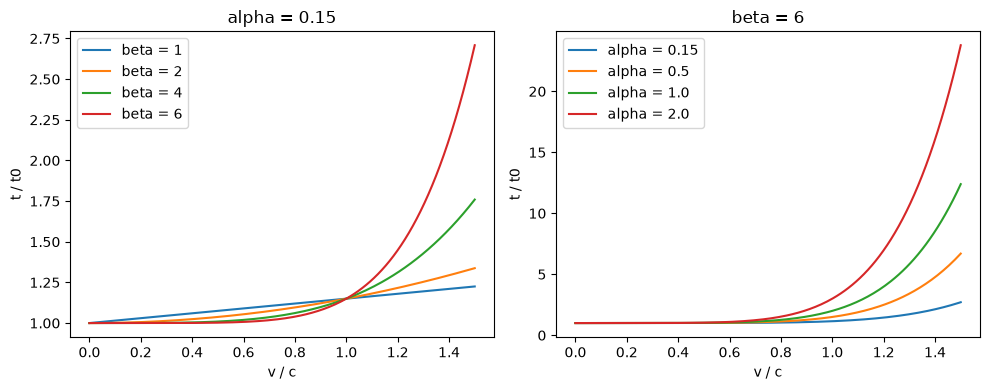

In [6]:
from types import SimpleNamespace

flow = np.linspace(0, 1.5, 200)  # with capacity = 1, flow equals v / c

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

# Vary beta, fixed alpha
for beta in (1, 2, 4, 6):
    links = SimpleNamespace(fftt=1.0, alpha=0.15, capacity=1.0, beta=beta)
    ax1.plot(flow, bpr_time(links, flow), label=f"beta = {beta}")
ax1.set_title("alpha = 0.15")

# Vary alpha, fixed beta
for alpha in (0.15, 0.5, 1.0, 2.0):
    links = SimpleNamespace(fftt=1.0, alpha=alpha, capacity=1.0, beta=6)
    ax2.plot(flow, bpr_time(links, flow), label=f"alpha = {alpha}")
ax2.set_title("beta = 6")

for ax in (ax1, ax2):
    ax.set_xlabel("v / c")
    ax.set_ylabel("t / t0")
    ax.legend()

plt.tight_layout()

In [34]:
run_assignment(sf, traffic_assignment(traffic_class(sf, build_graph(sf), "sioux-falls_demand"), "SO"), "ae_so")

links = load_links(sf)
ue_flow, so_flow = link_flows(sf, "ae_ue"), link_flows(sf, "ae_so")
total_time = lambda flow: (flow * bpr_time(links, flow)).sum()
print(f"total travel time  UE {total_time(ue_flow):,.0f}   SO {total_time(so_flow):,.0f}   UE / SO {total_time(ue_flow) / total_time(so_flow):.4f}")

total travel time  UE 7,474,789   SO 7,194,307   UE / SO 1.0390


The marginal social cost toll of a link is $v_a t_a'(v_a) = t^0_a \alpha_a \beta_a (v_a/c_a)^{\beta_a}$ at the system optimal flow. Charging it should make the user equilibrium equal to the system optimum.

AequilibraE adds `toll / vot` to the travel time of a link, so `vot` is in money per unit of time. These tolls are already in time units, hence `vot = 1`.

In [35]:
mscp = links.fftt * links.alpha * links.beta * (so_flow / links.capacity) ** links.beta

graph = build_graph(sf, tolls=mscp)
toll_before = graph.graph.toll.to_numpy().copy()
cars = traffic_class(sf, graph, "sioux-falls_demand", vot=1.0)
run_assignment(sf, traffic_assignment(cars, "UE"), "ae_tolled")
tolled_flow = link_flows(sf, "ae_tolled")

cmp = pd.DataFrame({"UE": ue_flow, "SO": so_flow, "tolled UE": tolled_flow, "toll": mscp})
cmp["tolled UE - SO"] = cmp["tolled UE"] - cmp.SO
print(f"largest |tolled UE - SO| link flow: {cmp['tolled UE - SO'].abs().max():.1f}  (largest |UE - SO|: {(cmp.UE - cmp.SO).abs().max():.1f})")
cmp.sort_values("toll", ascending=False).head(8).round(2)

largest |tolled UE - SO| link flow: 113.9  (largest |UE - SO|: 4299.0)


,UE,SO,tolled UE,toll,tolled UE - SO
link_id,,,,,
48,11069.04,10768.79,10763.48,58.10,-5.31
29,11039.43,10739.96,10739.54,57.48,-0.41
19,12522.12,12590.05,12579.99,52.36,-10.07
16,12492.97,12555.51,12556.05,51.79,0.54
74,11104.96,10543.65,10573.92,44.14,30.27
39,11109.78,10533.71,10570.93,43.98,37.22
30,8100.01,8333.98,8300.09,37.24,-33.90
51,8100.00,8328.97,8359.06,37.15,30.09


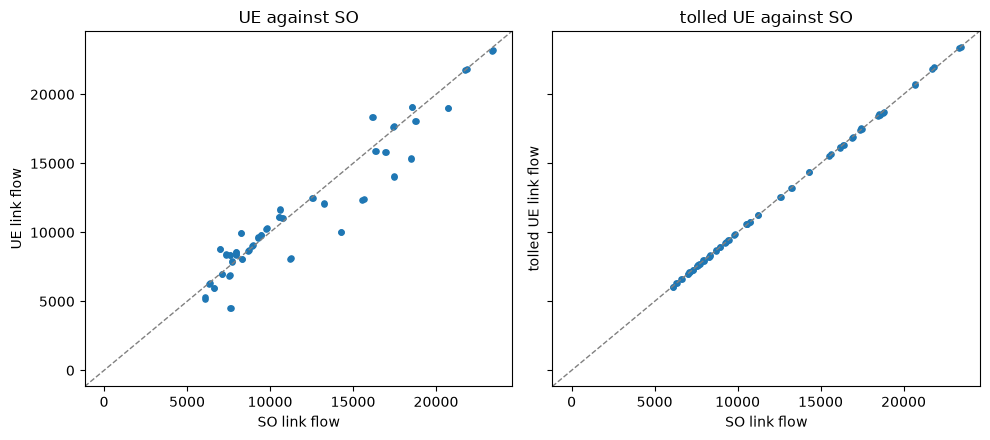

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharex=True, sharey=True)
for ax, column in zip(axes, ["UE", "tolled UE"]):
    ax.scatter(cmp.SO, cmp[column], s=14)
    ax.axline((0, 0), slope=1, color="grey", lw=1, ls="--")
    ax.set(xlabel="SO link flow", ylabel=f"{column} link flow", title=f"{column} against SO")
plt.tight_layout()

Does a tolled assignment change the tolls or the times?

In [37]:
tolled = sf.results.get_results("ae_tolled").set_index("link_id")
pd.Series({
    "toll field of the graph changed": not np.allclose(toll_before, graph.graph.toll),
    "links table has a toll column": "toll" in sf.network.links.data.columns,
    "Congested_Time_AB is the BPR time, without the toll": np.allclose(tolled.Congested_Time_AB, bpr_time(links, tolled_flow)),
    "class fixed cost equals toll / vot": np.allclose(cars.fixed_cost[graph.graph.__supernet_id__], graph.graph.toll / cars.vot),
}).to_frame("")

,
toll field of the graph changed,False
links table has a toll column,False
"Congested_Time_AB is the BPR time, without the toll",True
class fixed cost equals toll / vot,True


**Note.** Tolls behave like the free-flow time: the `toll` field of the graph is read and left alone, and it never reaches the project database because it only exists on the graph. The toll is turned into time once (`fixed_cost = toll / vot`) and added to the congested time when shortest paths are searched. The saved `Congested_Time_AB` is the travel time alone, so the toll paid on a route has to be added separately.

A flat toll shows the role of the value of time. One unit of money on every link with `vot = 0.25` money per minute costs 4 minutes per link, which pushes traffic onto routes with fewer links.

In [ ]:
# TOLL = 1.0   # the same toll on every link (money)
# VOT = 0.25   # value of time, the same for all users (money per minute)

# flat = pd.Series(TOLL, index=links.index)
# run_assignment(sf, traffic_assignment(traffic_class(sf, build_graph(sf, tolls=flat), "sioux-falls_demand", vot=VOT), "UE"), "ae_flat_toll")
# flat_flow = link_flows(sf, "ae_flat_toll")
# print(f"total travel time: no toll {total_time(ue_flow):,.0f}, flat toll {total_time(flat_flow):,.0f}")
# print(f"links used per trip: no toll {ue_flow.sum() / sf_demand.to_numpy().sum():.3f}, flat toll {flat_flow.sum() / sf_demand.to_numpy().sum():.3f}")

total travel time: no toll 7,474,789, flat toll 7,711,157
links used per trip: no toll 2.435, flat toll 2.393


## 4. Route flows from link flows

An assignment gives link flows. the flows are needed per O-D pair and route for fairness analysis. They can be recovered from the link flows in two steps.
Refer: Network Flows Book by Ahuja, orlin 
**Step 1, split the link flows by origin.** A small linear programme with the variables $x^o_a \ge 0$, the flow from origin $o$ on link $a$:

$$\min \sum_o \sum_a t_a x^o_a \quad \text{s.t.} \quad \text{flow conservation for every origin}, \qquad \sum_o x^o_a \le v_a .$$


**Step 2, peel off routes (flow decomposition).** For one origin and one destination, walk back from the destination to the origin, always taking the entering link that still carries most flow. Send as much as the route and the remaining trips allow, take it off the links, and repeat. Every pass empties a link or a destination, so there are at most (links + destinations) routes per origin. 

Link flows do not determine route flows uniquely. The decomposition returns one valid set.

In [7]:
def load_demand(project, matrix_name):
    """Positive O-D demand of a project matrix, indexed by (origin, destination)."""
    demand = demand_df(project, matrix_name).stack().rename("demand").rename_axis(["origin", "destination"])
    origin, destination = demand.index.get_level_values(0), demand.index.get_level_values(1)
    return demand[(demand > 0) & (origin != destination)]


def origin_flows(links, demand, flow):
    """Split link flows by origin (step 1). Returns a table with links as rows and origins as columns."""
    nodes = sorted(set(links.a_node) | set(links.b_node))
    out_links, in_links = links.groupby("a_node").groups, links.groupby("b_node").groups
    origins = sorted(demand.index.unique("origin"))

    model = gp.Model("origin_flows", env=gp.Env(params={"OutputFlag": 0}))
    x = model.addVars(origins, links.index, name="x")
    for o in origins:
        trips = demand.xs(o, level="origin") # data frame has demands from o to all othr links
        for node in nodes:
            net = trips.sum() if node == o else -trips.get(node, 0.0)
            leaving = gp.quicksum(x[o, a] for a in out_links.get(node, []))
            entering = gp.quicksum(x[o, a] for a in in_links.get(node, []))
            model.addConstr(leaving - entering == net)
    slack = 1e-6 * demand.sum()
    model.addConstrs(x.sum("*", a) <= max(flow[a], 0.0) + slack for a in links.index)
    time = bpr_time(links, flow)
    model.setObjective(gp.quicksum(time[a] * x[o, a] for o, a in x))
    model.optimize()
    return pd.DataFrame({o: [max(x[o, a].X, 0.0) for a in links.index] for o in origins}, index=links.index)


def peel_paths(flow, tail, in_links, origin, trips, tolerance):
    """Decompose the link flow of one origin into route flows (step 2). `flow` is consumed.

    Returns a list of (destination, route as a tuple of link ids, flow).
    """
    paths = []
    for destination, remaining in trips.items():
        while remaining > tolerance:
            path, node = [], destination
            while node != origin and len(path) <= len(flow):
                link = max(in_links.get(node, []), key=flow.get, default=None)
                if link is None:
                    break
                path.append(link)
                node = tail[link]
            sent = min([remaining] + [flow[a] for a in path]) if node == origin else 0.0
            if sent <= tolerance:
                break
            for a in path:
                flow[a] -= sent
            remaining -= sent
            paths.append((destination, tuple(reversed(path)), sent))
    return paths


def path_flows(project, matrix_name, table_name):
    """Route flows for the link flows of a results table: origin, destination, path, flow, time."""
    links, demand, flow = load_links(project), load_demand(project, matrix_name), link_flows(project, table_name)
    by_origin = origin_flows(links, demand, flow)
    tail = links.a_node.to_dict()
    in_links = {node: list(ids) for node, ids in links.groupby("b_node").groups.items()}
    time = bpr_time(links, flow)
    rows = []
    for origin in by_origin.columns:
        trips = demand.xs(origin, level="origin").to_dict()
        for destination, path, sent in peel_paths(by_origin[origin].to_dict(), tail, in_links, origin, trips, 1e-6 * demand.sum()):
            rows.append((origin, destination, path, sent, time[list(path)].sum()))
    return pd.DataFrame(rows, columns=["origin", "destination", "path", "flow", "time"])

In [9]:
ue_paths = path_flows(sf, "sioux-falls_demand", "ae_ue")
so_paths = path_flows(sf, "sioux-falls_demand", "ae_so")
print(f"routes used: UE {len(ue_paths)}, SO {len(so_paths)}, for {len(load_demand(sf, 'sioux-falls_demand'))} O-D pairs")
ue_paths.head()

routes used: UE 563, SO 566, for 528 O-D pairs


,origin,destination,path,flow,time
0,1,2,"(1,)",100.0,6.000813
1,1,3,"(2,)",100.0,4.008684
2,1,4,"(2, 6)",500.0,8.280663
3,1,5,"(2, 6, 9)",200.0,10.598535
4,1,6,"(1, 4)",300.0,12.570162


checks: the route flows carry all the demand, and adding them back up gives the link flows.

In [41]:
def links_from_paths(paths, index):
    flow = pd.Series(0.0, index=index)
    for path, f in zip(paths.path, paths.flow):
        flow[list(path)] += f
    return flow

for name, paths, flow in [("UE", ue_paths, ue_flow), ("SO", so_paths, so_flow)]:
    print(f"{name}: demand carried {paths.flow.sum():,.1f} of {sf_demand.to_numpy().sum():,.1f}, "
          f"largest link flow difference {(links_from_paths(paths, links.index) - flow).abs().max():.4f}")

UE: demand carried 360,599.7 of 360,600.0, largest link flow difference 0.2522
SO: demand carried 360,599.5 of 360,600.0, largest link flow difference 0.6682


At the user equilibrium the used routes of an O-D pair take the same time (Wardrop). At the system optimum they do not: some travellers are sent the long way round for the benefit of others. Marginal cost tolls make up the difference, so that time plus toll is equal again.

In [42]:
def od_routes(paths, origin, destination, tolls=None):
    routes = paths[(paths.origin == origin) & (paths.destination == destination)].copy()
    if tolls is not None:
        routes["toll"] = [tolls[list(path)].sum() for path in routes.path]
        routes["time + toll"] = routes.time + routes.toll
    return routes.round(2)

spread = lambda paths: paths.groupby(["origin", "destination"]).time.agg(lambda t: t.max() / t.min())
o, d = spread(so_paths).idxmax()  # the O-D pair whose SO routes differ most in time

display(od_routes(ue_paths, o, d))
display(od_routes(so_paths, o, d, tolls=mscp))

,origin,destination,path,flow,time
375,16,19,"(49, 53)",1204.87,16.85
376,16,19,"(50, 56, 61)",95.13,16.91


,origin,destination,path,flow,time,toll,time + toll
375,16,19,"(49, 53)",1197.81,11.62,30.50,42.12
376,16,19,"(50, 56, 61)",102.19,17.23,24.91,42.14


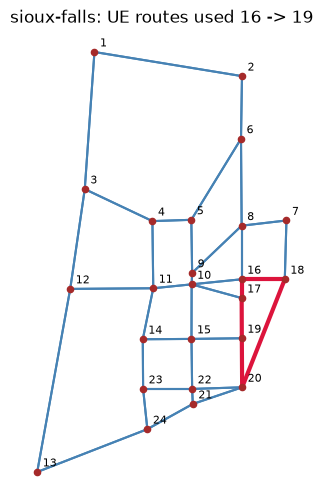

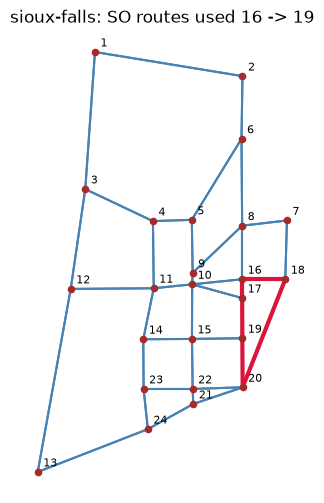

In [43]:
plot_network(sf, f"sioux-falls: UE routes used {o} -> {d}", routes=list(od_routes(ue_paths, o, d).path))
plot_network(sf, f"sioux-falls: SO routes used {o} -> {d}", routes=list(od_routes(so_paths, o, d).path));

In [44]:
pd.DataFrame({"UE": spread(ue_paths).describe(), "SO": spread(so_paths).describe()}).loc[["mean", "max"]].rename_axis("slowest / fastest used route").round(4)

,UE,SO
slowest / fastest used route,,
mean,1.0007,1.0091
max,1.1080,1.4820


At the UE the spread is 1 on average. The few pairs above 1 carry a small leftover flow on a slower route, which is what a relative gap of 1e-4 (`rgap` in `parameters.yml`) still allows. At the SO the slowest used route of some O-D pair is clearly longer than the fastest one, by design.

## Testing on a simple 4 link network (Braess Network)  
The saved tables `ae_ue`, `ae_so` and `ae_tolled` are used by `gurobi_expts.ipynb`.

In [45]:
for objective in ("UE", "SO"):
    run_assignment(hearn, traffic_assignment(traffic_class(hearn, build_graph(hearn), "hearn-example_demand"), objective), f"ae_{objective.lower()}")
    print(objective)
    display(path_flows(hearn, "hearn-example_demand", f"ae_{objective.lower()}").round(2))

# Tolled UE with marginal cost tolls, as for Sioux Falls
hearn_links, hearn_so = load_links(hearn), link_flows(hearn, "ae_so")
hearn_mscp = hearn_links.fftt * hearn_links.alpha * hearn_links.beta * (hearn_so / hearn_links.capacity) ** hearn_links.beta
run_assignment(hearn, traffic_assignment(traffic_class(hearn, build_graph(hearn, tolls=hearn_mscp), "hearn-example_demand"), "UE"), "ae_tolled")
pd.DataFrame({"SO": hearn_so, "toll": hearn_mscp, "tolled UE": link_flows(hearn, "ae_tolled")}).round(2)

UE


,origin,destination,path,flow,time
0,1,4,"(1, 5, 4)",4000.0,82.01


SO


,origin,destination,path,flow,time
0,1,4,"(2, 4)",1800.5,67.99
1,1,4,"(1, 3)",1800.5,67.99
2,1,4,"(1, 5, 4)",399.0,46.00


,SO,toll,tolled UE
link_id,,,
1,2199.5,21.99,2202.07
2,1800.5,0.00,1797.93
3,1800.5,0.00,1797.93
4,2199.5,21.99,2202.07
5,399.0,0.00,404.14


Comment: At the UE all 4000 travellers take the shortcut 1-2-3-4 and need 82.01. At the SO only 399 do and need 46, while the others need 68 on the outer routes: everyone is faster than at the UE, but the cost to achieve system optimum is not equally borne.

## Connecting to the database
How to connect to AE project database directly instead of using the API?
Ans. Everything above is stored in two SQLite files per project. `project_database.sqlite` holds the network and a `results` table that lists every saved result. `results_database.sqlite` holds one table per result.

In [46]:
from aequilibrae.project.database_connection import database_connection

conn = database_connection("network")   # uses the project opened last (hearn was opened first, sf last)
conn_t = database_connection("transit")
conn_r = database_connection("results")

In [47]:
pd.read_sql("SELECT type, COUNT(name) FROM sqlite_master GROUP BY type", conn)

,type,COUNT(name)
0,index,48
1,table,47
2,trigger,136
3,view,6


In [48]:
pd.read_sql("SELECT table_name, procedure, timestamp FROM results", conn)

,table_name,procedure,timestamp
0,ae_ue,traffic assignment,2026-11-17 09:33:45.430965
1,ae_so,traffic assignment,2026-11-17 09:33:45.953767
2,ae_tolled,traffic assignment,2026-11-17 09:33:46.676792
3,ae_flat_toll,traffic assignment,2026-11-17 09:33:47.151588


In [49]:
pd.read_sql("SELECT name, type FROM sqlite_master WHERE type IN ('table','view') ORDER BY name", conn_r)

,name,type
0,ae_flat_toll,table
1,ae_so,table
2,ae_tolled,table
3,ae_ue,table


In [50]:
pd.read_sql("SELECT link_id, volume_ab, Congested_Time_AB FROM ae_ue LIMIT 5", conn_r)

,link_id,volume_ab,Congested_Time_AB
0,1,4490.833243,6.000813
1,2,8117.428581,4.008684
2,3,4517.433556,6.000833
3,4,5963.303184,6.569348
4,5,8090.828268,4.008570


In [51]:
for c in (conn, conn_t, conn_r):
    c.close()
hearn.close()
sf.close()